# Análisis exploratorio reproducible de los factores asociados a la supervivencia de pasajeros del Titanic

**Universidad:** Universidad Andrés Bello (UNAB)

**Programa:** Magíster en Ciencia de Datos e Inteligencia Artificial

**Asignatura:** MCDI503 - Exploración Inteligente para la Ciencia de Datos

**Evaluación:** Sumativa 1 - Fase 1

**Docente:** Raúl Alonso

**Integrantes:**
- Hernán Saavedra
- Lenin Morales Salas
- Rodrigo Gómez

## 1. Contexto del proyecto

El análisis exploratorio de datos (EDA) constituye una etapa fundamental en un proyecto de ciencia de datos, porque permite comprender la estructura, distribución, calidad y posibles relaciones presentes en un conjunto de datos.

En este proyecto se utilizará el dataset Titanic, disponible en la biblioteca Seaborn de Python, que contiene información de 891 pasajeros y 15 variables relacionadas con características demográficas, socioeconómicas y supervivencia.

El propósito es realizar un análisis exploratorio reproducible que permita identificar patrones, detectar problemas de calidad y fundamentar decisiones metodológicas antes de desarrollar análisis más avanzados.

El proceso exploratorio sigue un enfoque de EDA mínimo viable, orientado a formular preguntas, examinar la calidad de los datos, justificar las decisiones metodológicas y documentar los hallazgos de manera reproducible (Paraíso, 2026).

## 2. Objetivo general

Explorar las características de los pasajeros del Titanic mediante técnicas de análisis exploratorio de datos, identificando patrones asociados a la supervivencia y documentando las decisiones necesarias para garantizar la trazabilidad y reproducibilidad del proceso.

## 3. Preguntas exploratorias

1. ¿Cuál es la proporción de pasajeros que sobrevivieron?
2. ¿Existen diferencias en la supervivencia según el sexo?
3. ¿Cómo varía la supervivencia entre las distintas clases de pasajeros?
4. ¿Qué relación exploratoria existe entre la edad y la supervivencia?
5. ¿Qué variables presentan valores faltantes, redundancias o filas idénticas?
6. ¿Cómo se distribuyen edad, tarifa y tamaño familiar?
7. ¿Cómo varía la supervivencia según tamaño familiar y la tarifa según clase?

## 4. Alcance

El estudio tendrá un enfoque descriptivo y exploratorio. Se utilizarán estadísticas descriptivas, visualizaciones y análisis de calidad de datos.

Los resultados permitirán identificar asociaciones y patrones preliminares, sin establecer relaciones causales ni desarrollar modelos predictivos en esta fase.


El enfoque combina resúmenes robustos, visualizaciones y revisión de calidad antes del modelamiento, en línea con Bruce et al. (2020). La fuente de los registros es Waskom (s. f.).


## 5. Configuración del entorno de análisis

**Objetivo:** Preparar un entorno de trabajo reproducible para desarrollar el análisis exploratorio del dataset Titanic.

**Herramientas utilizadas:**
- Python: lenguaje de programación.
- Pandas: manipulación y análisis de datos.
- NumPy: operaciones numéricas.
- Matplotlib: generación de gráficos.
- Seaborn: visualización estadística.

**Acción:** Se importan las bibliotecas necesarias, se configura el estilo de las visualizaciones y se registran las versiones de las principales dependencias.

**Justificación:** La identificación de las herramientas y sus versiones, junto con el archivo `requirements.txt`, facilita la reproducción del análisis por parte de los integrantes del equipo.


Pandas facilita la manipulación tabular (The pandas development team, s. f.) y seaborn permite representar distribuciones y relaciones estadísticas (Waskom, 2021).


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)

print(f"Python     : {sys.version.split()[0]}")
print(f"pandas     : {pd.__version__}")
print(f"numpy      : {np.__version__}")
print(f"seaborn    : {sns.__version__}")
print(f"matplotlib : {matplotlib.__version__}")

Python     : 3.11.9
pandas     : 3.1.1
numpy      : 2.4.6
seaborn    : 0.13.2
matplotlib : 3.11.2



## 6. Carga y verificación del conjunto de datos

**Pregunta exploratoria:** ¿Cuál es la estructura inicial del conjunto de datos y qué información contiene?

**Acción:** Se carga el archivo `titanic.csv` almacenado en el repositorio del proyecto, utilizando Pandas.

**Justificación:** Se utiliza una copia local del dataset para asegurar que todos los integrantes trabajen con los mismos registros y facilitar la reproducibilidad del análisis.

**Fuente:** Dataset Titanic de Seaborn, disponible en https://github.com/mwaskom/seaborn-data.

**Resultado esperado:** Verificar la cantidad de observaciones, variables y primeros registros del conjunto de datos.


In [2]:

# ==================================================
# 6. CARGA DEL DATASET TITANIC
# ==================================================

from pathlib import Path
import pandas as pd

# Buscar la raíz del proyecto desde el directorio actual
directorio_actual = Path.cwd().resolve()

if (directorio_actual / "datos" / "titanic.csv").exists():
    raiz_proyecto = directorio_actual
elif (directorio_actual.parent / "datos" / "titanic.csv").exists():
    raiz_proyecto = directorio_actual.parent
else:
    raise FileNotFoundError(
        "No se encontró datos/titanic.csv. "
        "Verifica que abriste el proyecto correcto."
    )

# Definir la ruta y cargar el dataset
ruta_datos = raiz_proyecto / "datos" / "titanic.csv"
df = pd.read_csv(ruta_datos)

# Verificar dimensiones
print("Dataset Titanic cargado correctamente")
print(f"Registros: {df.shape[0]}")
print(f"Variables: {df.shape[1]}")

# Mostrar primeros cinco registros
display(df.head())

titanic_raw = df.copy(deep=True)
(raiz_proyecto / "figuras").mkdir(exist_ok=True)

Dataset Titanic cargado correctamente
Registros: 891
Variables: 15


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



## 7. Inspección inicial y diagnóstico de calidad de datos

**Pregunta exploratoria:** ¿Qué tipos de variables contiene el dataset Titanic y qué problemas iniciales de calidad podrían afectar el análisis?

**Acción:** Se examinan las dimensiones, los tipos de datos, los valores faltantes, los registros duplicados y las estadísticas descriptivas.

**Justificación:** Antes de aplicar transformaciones, es necesario conocer las características originales del conjunto de datos. Esto permite fundamentar las decisiones posteriores y evitar modificaciones arbitrarias.

**Criterio metodológico:** En esta etapa solamente se diagnostican los datos. No se eliminan registros ni se imputan valores faltantes hasta evaluar su magnitud y relevancia.


In [3]:

# ==================================================
# 7. INSPECCIÓN INICIAL DEL DATASET
# ==================================================

# 1. Dimensiones del dataset
print("1. DIMENSIONES")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

# 2. Información general y tipos de datos
print("\n2. INFORMACIÓN GENERAL")
df.info()

# 3. Estadísticas descriptivas numéricas
print("\n3. ESTADÍSTICAS DESCRIPTIVAS NUMÉRICAS")
display(df.describe())

# 4. Estadísticas descriptivas categóricas
print("\n4. ESTADÍSTICAS DESCRIPTIVAS CATEGÓRICAS")
display(df.describe(include=["object", "string", "bool", "category"]))

# 5. Diagnóstico de valores faltantes
print("\n5. VALORES FALTANTES")

faltantes = pd.DataFrame({
    "Variable": df.columns,
    "Cantidad_faltantes": df.isnull().sum().values,
    "Porcentaje_faltantes": (
        df.isnull().mean().values * 100
    ).round(2)
})

faltantes = faltantes.sort_values(
    by="Cantidad_faltantes",
    ascending=False
)

display(faltantes)

# 6. Identificación de registros duplicados
print("\n6. REGISTROS DUPLICADOS")
duplicados = df.duplicated().sum()
print(f"Cantidad de filas duplicadas: {duplicados}")


1. DIMENSIONES
Filas: 891
Columnas: 15

2. INFORMACIÓN GENERAL
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB

3. ESTADÍSTICAS DESCRIPTIVAS NUMÉRICAS


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



4. ESTADÍSTICAS DESCRIPTIVAS CATEGÓRICAS


,sex,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891,889,891,891,891,203,889,891,891
unique,2,3,3,3,2,7,3,2,2
top,male,S,Third,man,True,C,Southampton,no,True
freq,577,644,491,537,537,59,644,549,537



5. VALORES FALTANTES


,Variable,Cantidad_faltantes,Porcentaje_faltantes
11,deck,688,77.22
3,age,177,19.87
7,embarked,2,0.22
12,embark_town,2,0.22
2,sex,0,0.00
1,pclass,0,0.00
0,survived,0,0.00
6,fare,0,0.00
5,parch,0,0.00
4,sibsp,0,0.00



6. REGISTROS DUPLICADOS
Cantidad de filas duplicadas: 107


### Diccionario de variables
Tipo **técnico** (cómo lo guarda pandas) frente a tipo **estadístico** (cómo debe analizarse). Esta distinción determina el resumen y el gráfico adecuados.

In [4]:
tipo_estadistico = {
    "survived": "binaria (variable de interés)", "pclass": "categórica ordinal (1: primera, 2: segunda, 3: tercera)",
    "sex": "categórica nominal", "age": "numérica continua", "sibsp": "numérica discreta",
    "parch": "numérica discreta", "fare": "numérica continua", "embarked": "categórica nominal",
    "class": "categórica ordinal", "who": "categórica nominal", "adult_male": "binaria",
    "deck": "categórica nominal", "embark_town": "categórica nominal", "alive": "binaria",
    "alone": "binaria",
}
diccionario = pd.DataFrame({
    "tipo_pandas": titanic_raw.dtypes.astype(str),
    "tipo_estadistico": pd.Series(tipo_estadistico),
    "n_unicos": titanic_raw.nunique(),
    "n_nulos": titanic_raw.isna().sum(),
    "pct_nulos": (titanic_raw.isna().mean() * 100).round(1),
})

descripciones = {'survived': 'Supervivencia: 0 no, 1 sí', 'pclass': 'Clase del boleto: 1, 2 o 3', 'sex': 'Sexo registrado', 'age': 'Edad en años', 'sibsp': 'Hermanos y cónyuges a bordo', 'parch': 'Padres e hijos a bordo', 'fare': 'Tarifa registrada del boleto', 'embarked': 'Puerto de embarque: C, Q o S', 'class': 'Clase del boleto en texto', 'who': 'Categoría hombre, mujer o niño', 'adult_male': 'Indicador de hombre adulto', 'deck': 'Cubierta registrada', 'embark_town': 'Nombre del puerto de embarque', 'alive': 'Supervivencia en texto', 'alone': 'Sin hermanos, cónyuges, padres o hijos registrados a bordo'}
diccionario.insert(0, "descripcion", pd.Series(descripciones))
display(diccionario)

,descripcion,tipo_pandas,tipo_estadistico,n_unicos,n_nulos,pct_nulos
survived,"Supervivencia: 0 no, 1 sí",int64,binaria (variable de interés),2,0,0.0
pclass,"Clase del boleto: 1, 2 o 3",int64,"categórica ordinal (1: primera, 2: segunda, 3:...",3,0,0.0
sex,Sexo registrado,str,categórica nominal,2,0,0.0
age,Edad en años,float64,numérica continua,88,177,19.9
sibsp,Hermanos y cónyuges a bordo,int64,numérica discreta,7,0,0.0
parch,Padres e hijos a bordo,int64,numérica discreta,7,0,0.0
fare,Tarifa registrada del boleto,float64,numérica continua,248,0,0.0
embarked,"Puerto de embarque: C, Q o S",str,categórica nominal,3,2,0.2
class,Clase del boleto en texto,str,categórica ordinal,3,0,0.0
who,"Categoría hombre, mujer o niño",str,categórica nominal,3,0,0.0



### 7.1. Interpretación del diagnóstico inicial

El conjunto de datos Titanic contiene 891 observaciones y 15 variables, incluyendo características demográficas, socioeconómicas y relacionadas con la supervivencia.

**Supervivencia:** Se observa una tasa general de supervivencia del 38,38 %, equivalente a 342 pasajeros. Este resultado constituye una referencia inicial para las comparaciones posteriores según sexo, clase y edad.

**Edad:** La edad promedio de los 714 pasajeros con información disponible es de 29,70 años, con una mediana de 28 años y una desviación estándar de 14,53 años. Sin embargo, 177 registros (19,87 %) carecen de esta información, lo que limita las conclusiones sobre la distribución etaria del conjunto completo.

**Tarifa:** La tarifa promedio es de 32,20, mientras que su mediana es de 14,45. Esta diferencia sugiere una posible asimetría positiva, que deberá examinarse mediante visualizaciones.

**Valores faltantes:** La variable `deck` presenta 688 valores faltantes (77,22 %), por lo que su utilización en el análisis principal sería limitada. La variable `age` presenta un porcentaje relevante de ausencia de datos, mientras que `embarked` y `embark_town` registran solamente dos valores faltantes cada una.

**Registros duplicados:** Se identificaron 107 filas adicionales con valores idénticos en todas las columnas. No obstante, dado que el dataset no dispone de un identificador único de pasajero, no es posible determinar si corresponden a duplicaciones reales. Por esta razón, no se eliminarán automáticamente.



## 8. Decisiones y transformaciones (pregunta 5)
Se trabaja sobre una copia independiente. Las decisiones siguientes son la propuesta metodológica de integración, sujeta a ratificación del equipo. Se conservan los datos originales.

In [5]:
titanic_eda = titanic_raw.copy()
registro_decisiones = []

def registrar(id_dec, tema, decision, justificacion, efecto):
    registro_decisiones.append({"ID": id_dec, "Tema": tema, "Decisión": decision,
                                "Justificación": justificacion, "Resultado intermedio": efecto})

### D1. Filas idénticas
Sin identificador individual no se puede confirmar duplicación real. Se conservan todas las filas.

Eliminar filas idénticas reduciría el tamaño de la muestra sin garantizar que se eliminen registros de la misma persona. Se privilegia conservar información y documentar la incertidumbre.


In [6]:
dup_mask = titanic_raw.duplicated(keep=False)
print("Filas duplicadas exactas:", titanic_raw.duplicated().sum())
print("Filas involucradas en duplicados:", dup_mask.sum())
print("¿Existe columna identificadora (passengerid, name, ticket)?",
      any(c in titanic_raw.columns for c in ["passengerid", "name", "ticket"]))
titanic_raw[dup_mask].sort_values(list(titanic_raw.columns)).head(6)

Filas duplicadas exactas: 107
Filas involucradas en duplicados: 160
¿Existe columna identificadora (passengerid, name, ticket)? False


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
64,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
295,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
144,0,2,male,18.0,0,0,11.5000,S,Second,man,True,NaN,Southampton,no,True
757,0,2,male,18.0,0,0,11.5000,S,Second,man,True,NaN,Southampton,no,True
658,0,2,male,23.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
733,0,2,male,23.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True


In [7]:
registrar("D1", "Filas idénticas", "Conservar", "No existe identificador individual", f"Filas: {len(titanic_eda)}")

### D2. Redundancia
Se conservan survived, class y embarked por su utilidad interpretativa. alone se mantiene como indicador derivado para comprobación, no como información independiente.

Las tablas cruzadas respaldan la selección de una representación por concepto. `who` y `adult_male` se conservan como atributos auxiliares relacionados con sexo y edad, no como variables independientes por definición.


In [8]:
for a, b in [("survived", "alive"), ("pclass", "class"), ("embarked", "embark_town")]:
    print(f"\n{a} vs {b}")
    print(pd.crosstab(titanic_raw[a], titanic_raw[b]))

print("\n'alone' coincide con (sibsp + parch == 0):",
      (titanic_raw["alone"] == ((titanic_raw["sibsp"] + titanic_raw["parch"]) == 0)).all())


survived vs alive
alive      no  yes
survived          
0         549    0
1           0  342

pclass vs class
class   First  Second  Third
pclass                      
1         216       0      0
2           0     184      0
3           0       0    491

embarked vs embark_town
embark_town  Cherbourg  Queenstown  Southampton
embarked                                       
C                  168           0            0
Q                    0          77            0
S                    0           0          644

'alone' coincide con (sibsp + parch == 0): True


In [9]:
titanic_eda = titanic_eda.drop(columns=["alive", "pclass", "embark_town"])
registrar("D2", "Redundancia", "Excluir alive, pclass, embark_town", "Recodificaciones de variables conservadas", f"Columnas: {titanic_eda.shape[1]}")

### D3. Cubierta
Se excluye deck de la copia por su elevada ausencia y su distribución desigual entre clases.

La ausencia de cubierta alcanza 19,0 %, 91,3 % y 97,6 % en primera, segunda y tercera clase, respectivamente. Imputar o asignar una categoría desconocida son alternativas, pero no recuperan la cubierta real. Se excluye del análisis principal sin eliminar pasajeros.


In [10]:
(titanic_raw.assign(deck_faltante=titanic_raw["deck"].isna())
            .groupby("pclass")["deck_faltante"].mean().mul(100).round(1)
            .rename("% deck faltante por clase"))

pclass
1    19.0
2    91.3
3    97.6
Name: % deck faltante por clase, dtype: float64

In [11]:
titanic_eda = titanic_eda.drop(columns=["deck"])
registrar("D3", "Cubierta", "Excluir deck", "77,22 % faltante", f"Columnas: {titanic_eda.shape[1]}")

### D4. Edad
Se mantienen los nulos; se utilizan casos disponibles para edad. La ausencia desigual por clase puede sesgar las comparaciones.

La ausencia de edad es 13,9 %, 6,0 % y 27,7 % por clase. Imputar con la media podría reducir artificialmente la dispersión; eliminar filas de todo el análisis descartaría información válida de otras variables. Se utilizan 714 casos disponibles únicamente para comparaciones de edad. La distribución desigual de faltantes no demuestra por sí sola un mecanismo específico de ausencia.


In [12]:
(titanic_raw.assign(age_faltante=titanic_raw["age"].isna())
            .groupby("pclass")["age_faltante"].mean().mul(100).round(1)
            .rename("% age faltante por clase"))

pclass
1    13.9
2     6.0
3    27.7
Name: % age faltante por clase, dtype: float64

In [13]:
registrar("D4", "Edad", "Sin imputación", "Evitar alterar la distribución observada", f"Nulos: {titanic_eda.age.isna().sum()}")

### D5. Puerto de embarque
Se mantienen los dos registros con puerto desconocido para no perder información de otras variables.

In [14]:
display(titanic_raw[titanic_raw.embarked.isna()])
registrar("D5", "Embarque", "Conservar nulos", "No es variable central", f"Nulos: {titanic_eda.embarked.isna().sum()}")

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
61,1,1,female,38.0,0,0,80.0,NaN,First,woman,False,B,NaN,yes,True
829,1,1,female,62.0,0,0,80.0,NaN,First,woman,False,B,NaN,yes,True


### D6. Variable derivada: tamaño del grupo familiar a bordo  ·  *(preguntas 6 y 7)*
El dataset separa el número de hermanos/cónyuges (`sibsp`) y padres/hijos (`parch`). Analizarlos por separado puede ocultar si un pasajero viajaba acompañado por un grupo familiar amplio o completamente solo. Por eso construimos:

$$
family\_size = sibsp + parch + 1
$$

donde se suma `1` para incluir al propio pasajero. La variable se crea en `titanic_eda` (no en los datos originales).

In [15]:
titanic_eda["family_size"] = titanic_eda["sibsp"] + titanic_eda["parch"] + 1
registrar("D6", "Variable derivada", "Se crea family_size = sibsp + parch + 1",
          "Resume en una sola medida el tamaño del grupo familiar a bordo",
          f"family_size: rango {titanic_eda['family_size'].min()}–{titanic_eda['family_size'].max()}")
titanic_eda[["sibsp", "parch", "family_size", "alone"]].head(10)

,sibsp,parch,family_size,alone
0,1,0,2,False
1,1,0,2,False
2,0,0,1,True
3,1,0,2,False
4,0,0,1,True
5,0,0,1,True
6,0,0,1,True
7,3,1,5,False
8,0,2,3,False
9,1,0,2,False


In [16]:
pd.DataFrame({
    "titanic_raw": [titanic_raw.shape[0], titanic_raw.shape[1], int(titanic_raw.isna().sum().sum())],
    "titanic_eda": [titanic_eda.shape[0], titanic_eda.shape[1], int(titanic_eda.isna().sum().sum())],
}, index=["filas", "columnas", "nulos_totales"])

,titanic_raw,titanic_eda
filas,891,891
columnas,15,12
nulos_totales,869,179


In [17]:
display(pd.DataFrame(registro_decisiones))

,ID,Tema,Decisión,Justificación,Resultado intermedio
0,D1,Filas idénticas,Conservar,No existe identificador individual,Filas: 891
1,D2,Redundancia,"Excluir alive, pclass, embark_town",Recodificaciones de variables conservadas,Columnas: 12
2,D3,Cubierta,Excluir deck,"77,22 % faltante",Columnas: 11
3,D4,Edad,Sin imputación,Evitar alterar la distribución observada,Nulos: 177
4,D5,Embarque,Conservar nulos,No es variable central,Nulos: 2
5,D6,Variable derivada,Se crea family_size = sibsp + parch + 1,Resume en una sola medida el tamaño del grupo ...,family_size: rango 1–11


### 8.1. Variables auxiliares para visualización
Se ordena la clase y se agrupan tamaños familiares y edades. Los intervalos etarios son cerrados a la derecha; se conserva la edad continua.

**Variables auxiliares:** `family_group` agrupa tamaños 1, 2–4 y 5 o más para evitar fragmentar excesivamente los grupos; `age_group` utiliza intervalos cerrados a la derecha (0–12, más de 12 hasta 18, más de 18 hasta 35, más de 35 hasta 60 y más de 60); conserva las edades faltantes. `log_fare = log(1 + fare)` se incorpora en §11.4 para visualizar tarifas asimétricas sin perder ceros. Estas transformaciones no sustituyen las variables originales conservadas.


In [18]:
orden_clases = ["First", "Second", "Third"]
titanic_eda["class"] = pd.Categorical(titanic_eda["class"], categories=orden_clases, ordered=True)
titanic_eda["family_group"] = pd.cut(titanic_eda.family_size, [0,1,4,np.inf], labels=["Solo (1)", "Familia pequeña (2-4)", "Familia numerosa (5+)"])
titanic_eda["age_group"] = pd.cut(titanic_eda.age, [0,12,18,35,60,np.inf], include_lowest=True, labels=["0–12", ">12–18", ">18–35", ">35–60", ">60"])
assert titanic_raw.shape == (891,15)
assert len(titanic_eda) == 891
assert titanic_eda.age_group.notna().sum() == 714

## 9. Análisis univariado (pregunta 6)
Se examinan distribuciones, dispersión y valores extremos mediante histogramas, cajas y frecuencias. La regla IQR identifica observaciones para revisión, no errores confirmados.

In [19]:
num_cols = ["age", "sibsp", "parch", "fare", "family_size"]
resumen_num = titanic_eda[num_cols].describe().T
resumen_num["mediana"] = titanic_eda[num_cols].median()
resumen_num["IQR"] = resumen_num["75%"] - resumen_num["25%"]
resumen_num.round(2)

,count,mean,std,min,25%,50%,75%,max,mediana,IQR
age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00,28.00,17.88
sibsp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00,0.00,1.00
parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00,0.00,0.00
fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33,14.45,23.09
family_size,891.0,1.90,1.61,1.00,1.00,1.00,2.0,11.00,1.00,1.00


In [20]:
cat_cols = ["sex", "class", "embark_town", "who", "alone", "alive", "deck"]
for col in cat_cols:
    tabla = pd.DataFrame({
        "n": titanic_raw[col].value_counts(dropna=False),
        "%": (titanic_raw[col].value_counts(dropna=False, normalize=True) * 100).round(1),
    })
    print(f"\nFrecuencias de {col}:")
    print(tabla)


Frecuencias de sex:
          n     %
sex              
male    577  64.8
female  314  35.2

Frecuencias de class:
          n     %
class            
Third   491  55.1
First   216  24.2
Second  184  20.7

Frecuencias de embark_town:
               n     %
embark_town           
Southampton  644  72.3
Cherbourg    168  18.9
Queenstown    77   8.6
NaN            2   0.2

Frecuencias de who:
         n     %
who             
man    537  60.3
woman  271  30.4
child   83   9.3

Frecuencias de alone:
         n     %
alone           
True   537  60.3
False  354  39.7

Frecuencias de alive:
         n     %
alive           
no     549  61.6
yes    342  38.4

Frecuencias de deck:
        n     %
deck           
NaN   688  77.2
C      59   6.6
B      47   5.3
D      33   3.7
E      32   3.6
A      15   1.7
F      13   1.5
G       4   0.4


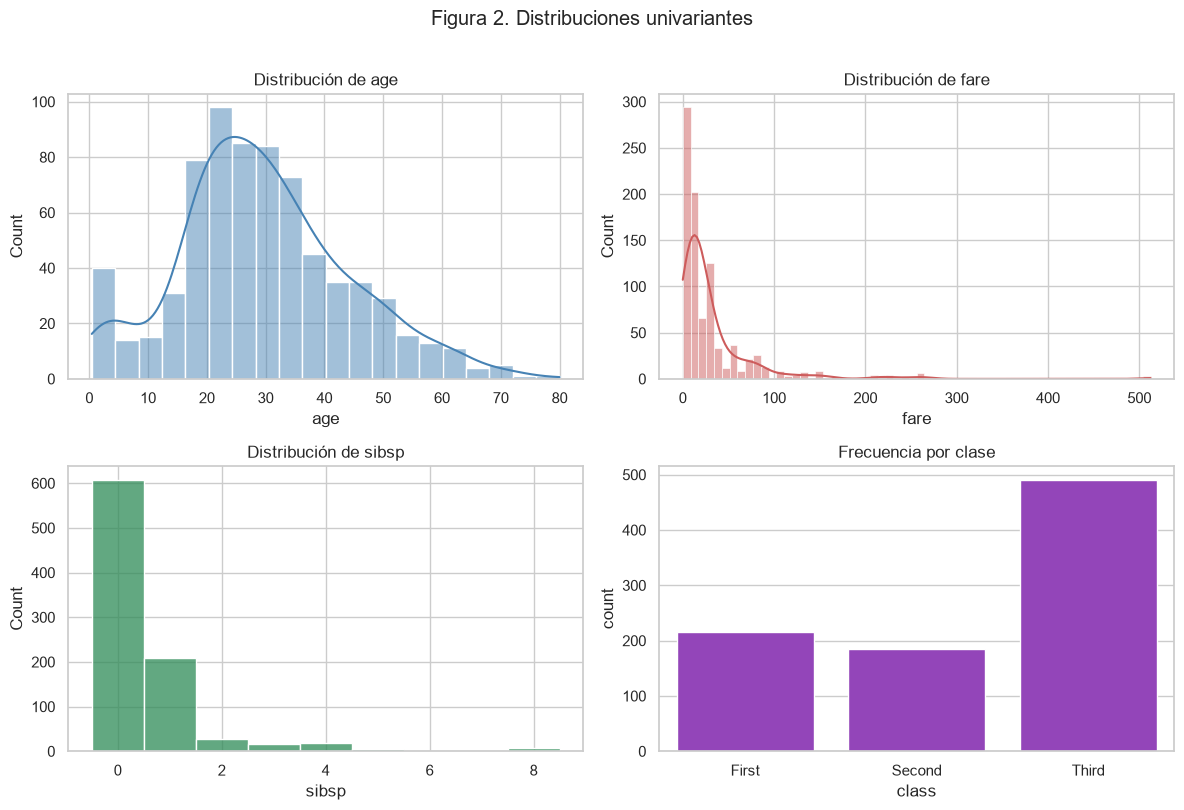

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(titanic_raw["age"].dropna(), kde=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Distribución de age")

sns.histplot(titanic_raw["fare"], kde=True, ax=axes[0, 1], color="indianred")
axes[0, 1].set_title("Distribución de fare")

sns.histplot(titanic_raw["sibsp"], discrete=True, ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Distribución de sibsp")

sns.countplot(data=titanic_raw, x="class", order=orden_clases, ax=axes[1, 1], color="darkorchid")
axes[1, 1].set_title("Frecuencia por clase")

fig.suptitle("Figura 2. Distribuciones univariantes", y=1.01)
plt.tight_layout()
fig.savefig(raiz_proyecto / "figuras" / "02_distribuciones.png", dpi=300, bbox_inches="tight")
plt.show()

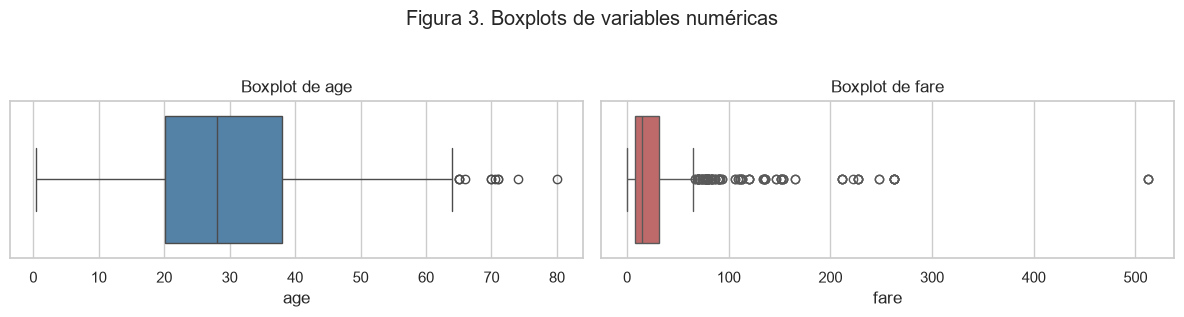

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))

sns.boxplot(x=titanic_raw["age"].dropna(), ax=axes[0], color="steelblue")
axes[0].set_title("Boxplot de age")

sns.boxplot(x=titanic_raw["fare"], ax=axes[1], color="indianred")
axes[1].set_title("Boxplot de fare")

fig.suptitle("Figura 3. Boxplots de variables numéricas", y=1.05)
plt.tight_layout()
fig.savefig(raiz_proyecto / "figuras" / "03_cajas.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
# Outliers según regla del IQR (1,5 × IQR): pistas a revisar, no errores a borrar
def contar_outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum())

pd.Series({c: contar_outliers_iqr(titanic_raw[c].dropna()) for c in ["age", "fare"]},
          name="n_outliers_IQR")

age      11
fare    116
Name: n_outliers_IQR, dtype: int64

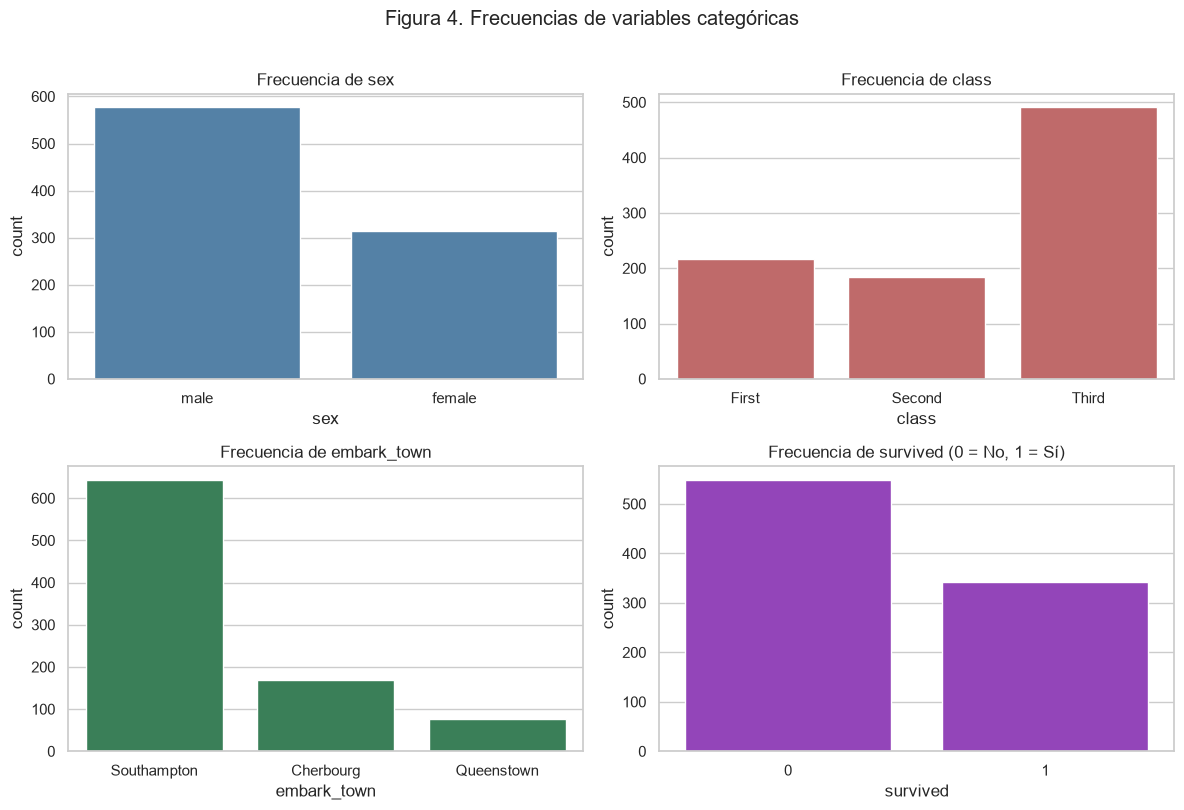

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.countplot(data=titanic_raw, x="sex", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Frecuencia de sex")

sns.countplot(data=titanic_raw, x="class", ax=axes[0, 1], color="indianred",
              order=["First", "Second", "Third"])
axes[0, 1].set_title("Frecuencia de class")

sns.countplot(data=titanic_raw, x="embark_town", ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Frecuencia de embark_town")

sns.countplot(data=titanic_raw, x="survived", ax=axes[1, 1], color="darkorchid")
axes[1, 1].set_title("Frecuencia de survived (0 = No, 1 = Sí)")

fig.suptitle("Figura 4. Frecuencias de variables categóricas", y=1.01)
plt.tight_layout()
fig.savefig(raiz_proyecto / "figuras" / "04_categoricas.png", dpi=300, bbox_inches="tight")
plt.show()

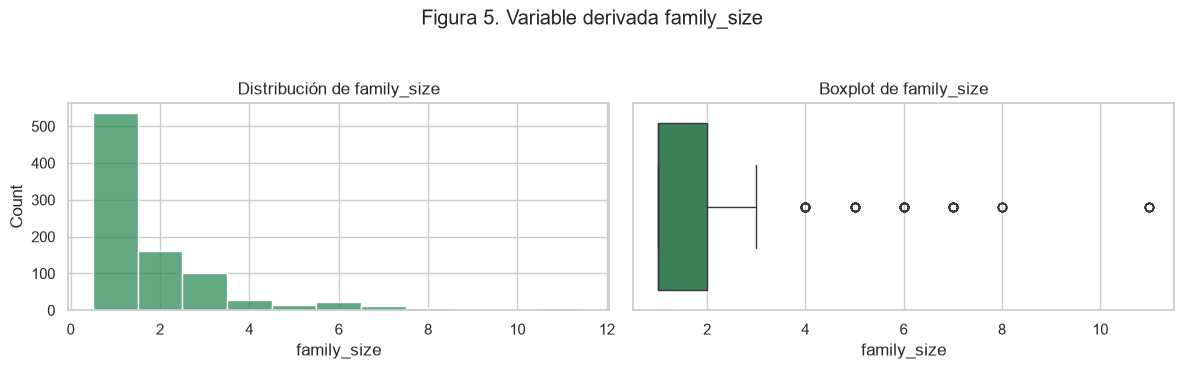

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(titanic_eda["family_size"], discrete=True, ax=axes[0], color="seagreen")
axes[0].set_title("Distribución de family_size")
sns.boxplot(x=titanic_eda["family_size"], ax=axes[1], color="seagreen")
axes[1].set_title("Boxplot de family_size")
fig.suptitle("Figura 5. Variable derivada family_size", y=1.05)
plt.tight_layout()
fig.savefig(raiz_proyecto / "figuras" / "05_familia.png", dpi=300, bbox_inches="tight")
plt.show()

La edad observada tiene media 29,70 y mediana 28 años. La tarifa tiene media 32,20 y mediana 14,45, coherentes con una cola derecha pronunciada. Los valores extremos no se eliminan sin evidencia de error. Predominan hombres (577 de 891), tercera clase (491 de 891) y pasajeros sin familiares registrados (537 de 891). Las comparaciones deben utilizar tasas dentro de cada grupo, no solo conteos absolutos.

La regla de 1,5 veces el rango intercuartílico (Bruce et al., 2020) identifica 11 edades extremas entre 714 observadas (1,54 %) y 116 tarifas extremas entre 891 registros (13,02 %). Son observaciones para revisar, no errores demostrados. La tarifa alcanza 512,33 y la edad 80 años; se conservan porque no existe evidencia suficiente para descartarlas. Los gráficos de caja complementan los histogramas al mostrar dispersión y colas.


## 10. Análisis general de supervivencia

### 10.1. Pregunta exploratoria

¿Cuál fue la proporción de pasajeros que sobrevivieron
y no sobrevivieron dentro del conjunto de datos analizado?

### Acción

Calcular las frecuencias absolutas y relativas de la
variable survived y representar gráficamente su distribución.

### Justificación

Conocer la distribución general de la supervivencia
permite establecer una referencia para las posteriores
comparaciones entre grupos de pasajeros.

Este análisis es descriptivo y no pretende establecer
relaciones causales.

In [26]:
# Frecuencias absolutas y relativas de supervivencia

tabla_supervivencia = pd.DataFrame({
    "Cantidad": titanic_eda["survived"].value_counts().sort_index(),
    "Porcentaje": (
        titanic_eda["survived"].value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
})

tabla_supervivencia.index = [
    "No sobrevivió",
    "Sobrevivió"
]

tabla_supervivencia.index.name = "Supervivencia"

display(tabla_supervivencia)

,Cantidad,Porcentaje
Supervivencia,,
No sobrevivió,549,61.62
Sobrevivió,342,38.38


### 10.2. Visualización de la supervivencia general

Se utiliza un gráfico de barras para representar las
frecuencias absolutas de supervivencia, incorporando
los porcentajes correspondientes a cada categoría.

La figura se almacena en la carpeta figuras del proyecto
para facilitar su reutilización en el informe final.

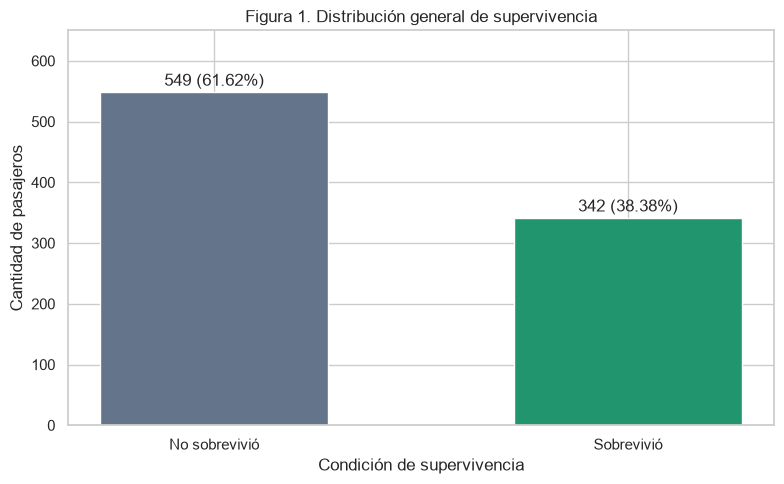

In [27]:
# Figura 1. Distribución general de supervivencia

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    tabla_supervivencia.index,
    tabla_supervivencia["Cantidad"],
    color=["#64748b", "#21956D"],
    width=0.55
)

for barra, porcentaje in zip(
    barras, tabla_supervivencia["Porcentaje"]
):
    cantidad = barra.get_height()

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        cantidad + 10,
        f"{int(cantidad)} ({porcentaje:.2f}%)",
        ha="center"
    )

ax.set_title("Figura 1. Distribución general de supervivencia")
ax.set_xlabel("Condición de supervivencia")
ax.set_ylabel("Cantidad de pasajeros")
ax.set_ylim(0, 650)

plt.tight_layout()

# Guardar figura en el repositorio
ruta_figura = raiz_proyecto / "figuras" / "01_supervivencia_general.png"

fig.savefig(ruta_figura, dpi=300, bbox_inches="tight")

plt.show()

### 10.3. Interpretación de los resultados

De los 891 pasajeros incluidos en el conjunto de datos,
342 sobrevivieron (38,38 %), mientras que 549 no
sobrevivieron (61,62 %).

Se observa una diferencia de 23,24 puntos porcentuales
entre ambas categorías, lo que evidencia un predominio
de los pasajeros que no sobrevivieron.

La tasa general de supervivencia del 38,38 % constituye
una referencia para los posteriores análisis comparativos
según sexo, clase del boleto, edad y tamaño del grupo
familiar.

Estos resultados corresponden exclusivamente a los
registros disponibles en el dataset y no deben
generalizarse a la totalidad de las personas que
viajaban a bordo del Titanic.

### Resultado de la pregunta exploratoria

La supervivencia presenta una distribución desigual,
con una mayor proporción de pasajeros que no
sobrevivieron dentro del conjunto de datos analizado.

## 11. Análisis bivariado
Se comparan tasas y tamaños de grupo sin pruebas de hipótesis ni atribución causal.

### 11.1. Sexo y clase (preguntas 2 y 3)
Se calculan tablas de contingencia con frecuencias absolutas ($n$), conteo de sobrevivientes y tasas porcentuales de supervivencia por sexo, por clase y en el cruce `class × sex`. Posteriormente se visualizan las tasas comparadas mediante gráficos de barras agrupadas.

Tabla 1A. Supervivencia marginal según sexo:


,Total_pasajeros,Sobrevivientes,Tasa_supervivencia
sex,,,
female,314,233,74.20
male,577,109,18.89



Tabla 1B. Supervivencia marginal según clase:


,Total_pasajeros,Sobrevivientes,Tasa_supervivencia
class,,,
First,216,136,62.96
Second,184,87,47.28
Third,491,119,24.24



Tabla 1C. Tasa de supervivencia (%) por Clase y Sexo:


sex,female,male
class,,
First,96.81,36.89
Second,92.11,15.74
Third,50.00,13.54



Tabla 1D. Cantidad de pasajeros (n) por Clase y Sexo:


sex,female,male
class,,
First,94,122
Second,76,108
Third,144,347


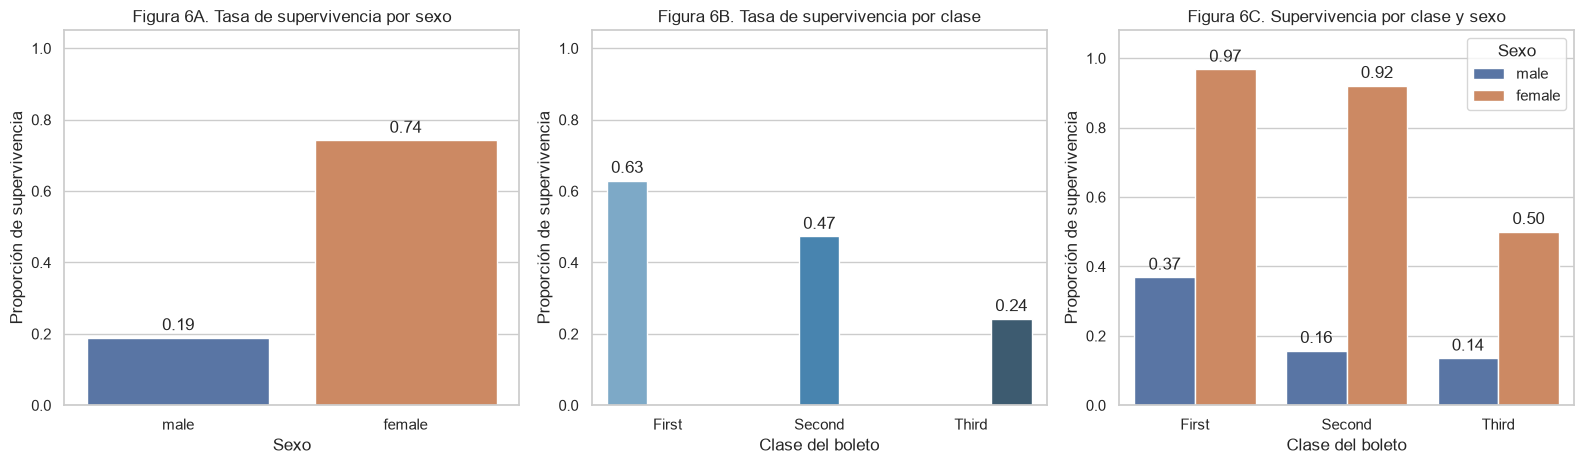

In [28]:
# ==================================================
# ANÁLISIS 1: SUPERVIVENCIA SEGÚN SEXO Y CLASE
# ==================================================

# 1. Resumen marginal por sexo
resumen_sexo = titanic_eda.groupby("sex", observed=False)["survived"].agg(
    Total_pasajeros="count",
    Sobrevivientes="sum",
    Tasa_supervivencia=lambda s: round(s.mean() * 100, 2)
)
print("Tabla 1A. Supervivencia marginal según sexo:")
display(resumen_sexo)

# 2. Resumen marginal por clase
resumen_clase = titanic_eda.groupby("class", observed=False)["survived"].agg(
    Total_pasajeros="count",
    Sobrevivientes="sum",
    Tasa_supervivencia=lambda s: round(s.mean() * 100, 2)
)
print("\nTabla 1B. Supervivencia marginal según clase:")
display(resumen_clase)

# 3. Tabla cruzada: Tasa de supervivencia (%) y tamaño muestral (n) por Clase y Sexo
tasa_cruzada = pd.pivot_table(
    titanic_eda, index="class", columns="sex", values="survived", aggfunc="mean", observed=False
) * 100

conteo_cruzado = pd.pivot_table(
    titanic_eda, index="class", columns="sex", values="survived", aggfunc="count", observed=False
)

print("\nTabla 1C. Tasa de supervivencia (%) por Clase y Sexo:")
display(tasa_cruzada.round(2))

print("\nTabla 1D. Cantidad de pasajeros (n) por Clase y Sexo:")
display(conteo_cruzado)

# 4. Visualización bivariada y multivariada
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Panel A: Supervivencia por Sexo
sns.barplot(
    data=titanic_eda, x="sex", y="survived", errorbar=None,
    palette=["#4C72B0", "#DD8452"], hue="sex", legend=False, ax=axes[0]
)
axes[0].set_title("Figura 6A. Tasa de supervivencia por sexo")
axes[0].set_xlabel("Sexo")
axes[0].set_ylabel("Proporción de supervivencia")
axes[0].set_ylim(0, 1.05)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.2f", padding=3)

# Panel B: Supervivencia por Clase
sns.barplot(
    data=titanic_eda, x="class", y="survived", errorbar=None,
    palette="Blues_d", hue="class", legend=False, ax=axes[1]
)
axes[1].set_title("Figura 6B. Tasa de supervivencia por clase")
axes[1].set_xlabel("Clase del boleto")
axes[1].set_ylabel("Proporción de supervivencia")
axes[1].set_ylim(0, 1.05)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f", padding=3)

# Panel C: Interacción Clase x Sexo
sns.barplot(
    data=titanic_eda, x="class", y="survived", hue="sex", errorbar=None,
    palette=["#4C72B0", "#DD8452"], ax=axes[2]
)
axes[2].set_title("Figura 6C. Supervivencia por clase y sexo")
axes[2].set_xlabel("Clase del boleto")
axes[2].set_ylabel("Proporción de supervivencia")
axes[2].set_ylim(0, 1.08)
axes[2].legend(title="Sexo")
for container in axes[2].containers:
    axes[2].bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
fig.savefig(raiz_proyecto / "figuras" / "06_sexo_clase.png", dpi=300, bbox_inches="tight")
plt.show()

Las mujeres presentan 74,20 % de supervivencia frente a 18,89 % de los hombres. Por clase, las tasas son 62,96 %, 47,28 % y 24,24 %. El cruce muestra diferencias descriptivas dentro de cada clase; no demuestra efectos independientes.

La brecha por sexo es 55,31 puntos porcentuales. Entre primera y tercera clase alcanza 38,72 puntos. En mujeres, las tasas por clase son 96,81 %, 92,11 % y 50,00 %; en hombres, 36,89 %, 15,74 % y 13,54 %. La comparación conjunta (figura 6) muestra que la diferencia por sexo persiste descriptivamente en las tres clases, aunque su magnitud cambia. Los denominadores de cada combinación deben considerarse antes de interpretar las tasas. No se han estimado efectos ajustados ni interacciones estadísticas.


### 11.2. Edad (pregunta 4)
Sobre los $n = 714$ registros con información válida de edad, se comparan las estadísticas descriptivas (media, mediana, rango intercuartílico) entre `survived = 0` y `survived = 1`, se calculan las tasas de supervivencia por tramo etario (`age_group`) y se visualizan mediante diagramas de caja, curvas de densidad superpuestas (KDE) y barras por grupo etario.

Registros válidos para análisis de edad: 714 de 891 (80.13 %)

Tabla 2A. Estadísticas de edad según supervivencia:


,n,Media,DE,Mediana,Q25,Q75,Min,Max
No sobrevivió (0),424,30.63,14.17,28.0,21.0,39.0,1.00,74.0
Sobrevivió (1),290,28.34,14.95,28.0,19.0,36.0,0.42,80.0



Tabla 2B. Supervivencia por grupo etario:


,Pasajeros_n,Sobrevivientes,Tasa_supervivencia
age_group,,,
0–12,69,40,57.97
>12–18,70,30,42.86
>18–35,358,137,38.27
>35–60,195,78,40.00
>60,22,5,22.73


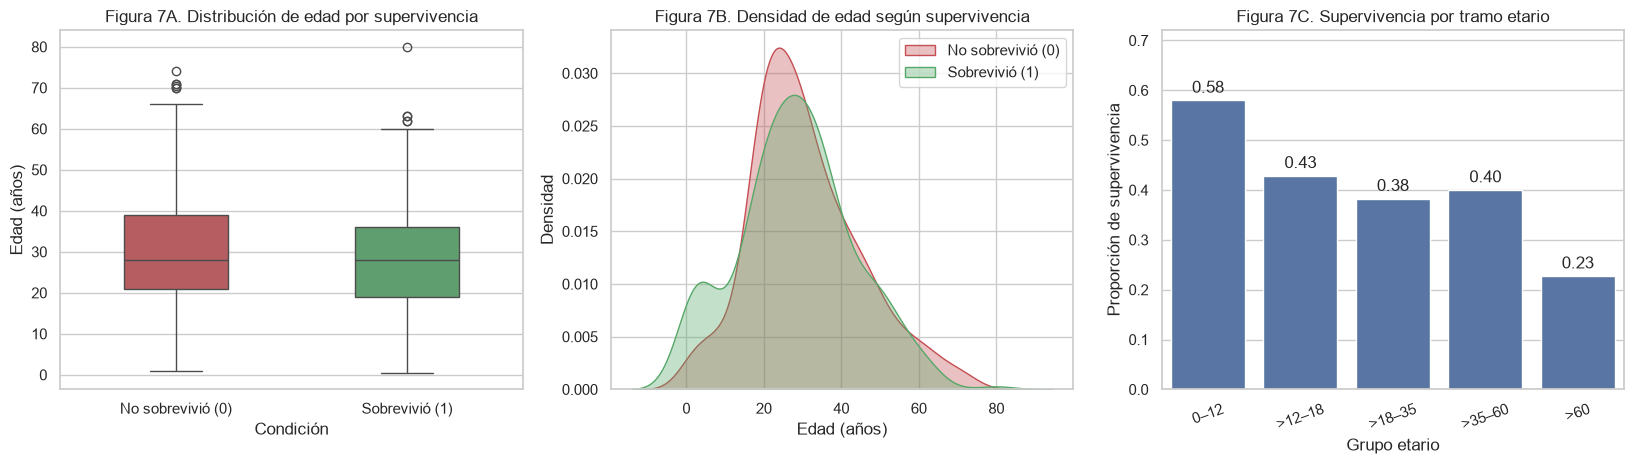

In [29]:
# ==================================================
# ANÁLISIS 2: SUPERVIVENCIA SEGÚN EDAD
# ==================================================

df_edad_valida = titanic_eda.dropna(subset=["age"]).copy()
print(f"Registros válidos para análisis de edad: {len(df_edad_valida)} de {len(titanic_eda)} ({len(df_edad_valida)/len(titanic_eda)*100:.2f} %)")

# 1. Estadísticas descriptivas de edad por condición de supervivencia
desc_edad_surv = df_edad_valida.groupby("survived")["age"].agg(
    n="count",
    Media=lambda s: round(s.mean(), 2),
    DE=lambda s: round(s.std(), 2),
    Mediana=lambda s: round(s.median(), 2),
    Q25=lambda s: round(s.quantile(0.25), 2),
    Q75=lambda s: round(s.quantile(0.75), 2),
    Min="min",
    Max="max"
)
desc_edad_surv.index = ["No sobrevivió (0)", "Sobrevivió (1)"]
print("\nTabla 2A. Estadísticas de edad según supervivencia:")
display(desc_edad_surv)

# 2. Tasa de supervivencia por tramo etario
resumen_tramos_edad = df_edad_valida.groupby("age_group", observed=False)["survived"].agg(
    Pasajeros_n="count",
    Sobrevivientes="sum",
    Tasa_supervivencia=lambda s: round(s.mean() * 100, 2)
)
print("\nTabla 2B. Supervivencia por grupo etario:")
display(resumen_tramos_edad)

# 3. Visualización
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# Panel A: Boxplot de edad por supervivencia
sns.boxplot(
    data=df_edad_valida, x="survived", y="age",
    palette=["#C44E52", "#55A868"], hue="survived", legend=False, width=0.45, ax=axes[0]
)
axes[0].set_title("Figura 7A. Distribución de edad por supervivencia")
axes[0].set_xticks([0, 1], ["No sobrevivió (0)", "Sobrevivió (1)"])
axes[0].set_xlabel("Condición")
axes[0].set_ylabel("Edad (años)")

# Panel B: Densidad KDE superpuesta
sns.kdeplot(
    data=df_edad_valida[df_edad_valida["survived"] == 0], x="age",
    fill=True, common_norm=False, color="#C44E52", alpha=0.35, label="No sobrevivió (0)", ax=axes[1]
)
sns.kdeplot(
    data=df_edad_valida[df_edad_valida["survived"] == 1], x="age",
    fill=True, common_norm=False, color="#55A868", alpha=0.35, label="Sobrevivió (1)", ax=axes[1]
)
axes[1].set_title("Figura 7B. Densidad de edad según supervivencia")
axes[1].set_xlabel("Edad (años)")
axes[1].set_ylabel("Densidad")
axes[1].legend()

# Panel C: Tasa de supervivencia por tramo etario
sns.barplot(
    data=df_edad_valida, x="age_group", y="survived", errorbar=None,
    color="#4C72B0", ax=axes[2]
)
axes[2].set_title("Figura 7C. Supervivencia por tramo etario")
axes[2].set_xlabel("Grupo etario")
axes[2].set_ylabel("Proporción de supervivencia")
axes[2].set_ylim(0, 0.72)
axes[2].tick_params(axis="x", rotation=20)
for container in axes[2].containers:
    axes[2].bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
fig.savefig(raiz_proyecto / "figuras" / "07_edad.png", dpi=300, bbox_inches="tight")
plt.show()

Entre los 714 casos con edad conocida, ambas medianas son 28 años. Las medias son 28,34 en sobrevivientes y 30,63 en no sobrevivientes. El tramo hasta 12 años presenta 57,97 % y el superior a 60 años 22,73 % (22 casos). La ausencia de edad limita la comparación.

Los tramos intermedios registran 42,86 %, 38,27 % y 40,00 %, respectivamente. La diferencia entre los extremos es 35,24 puntos porcentuales, pero el tramo mayor de 60 años solo contiene 22 casos. La igualdad de medianas no implica igualdad de distribuciones. Los resultados de la figura 7 sugieren explorar relaciones no lineales en una fase posterior, considerando el posible sesgo por edades faltantes.


### 11.3. Tamaño familiar (pregunta 7)
Se tabula la frecuencia de pasajeros y la proporción de supervivencia para cada valor exacto de `family_size` (de 1 a 11 integrantes) y para la agrupación categórica `family_group` (*Solo*, *Familia pequeña 2-4*, *Familia numerosa 5+*), acompañando los resultados con visualizaciones comparativas.

Tabla 3A. Supervivencia según tamaño exacto del grupo familiar (family_size):


,Pasajeros_n,Sobrevivientes,Tasa_supervivencia
family_size,,,
1,537,163,30.35
2,161,89,55.28
3,102,59,57.84
4,29,21,72.41
5,15,3,20.00
6,22,3,13.64
7,12,4,33.33
8,6,0,0.00
11,7,0,0.00



Tabla 3B. Supervivencia por categoría de grupo familiar:


,Pasajeros_n,Porcentaje_muestra,Sobrevivientes,Tasa_supervivencia
family_group,,,,
Solo (1),537,60.27,163,30.35
Familia pequeña (2-4),292,32.77,169,57.88
Familia numerosa (5+),62,6.96,10,16.13


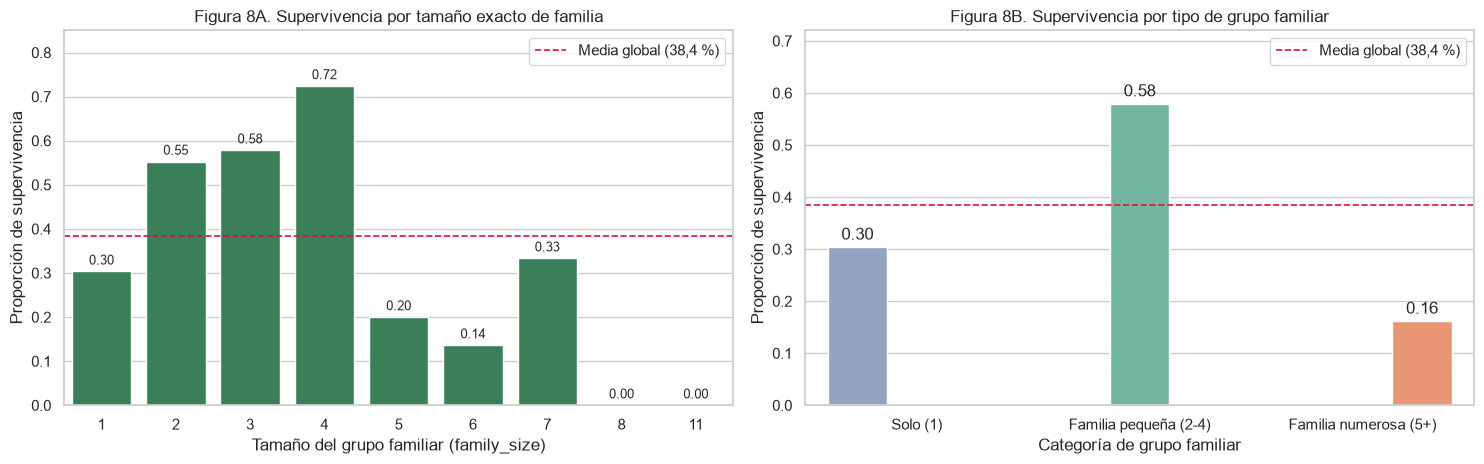

In [30]:
# ==================================================
# ANÁLISIS 3: SUPERVIVENCIA SEGÚN TAMAÑO DE FAMILIA
# ==================================================

# 1. Desglose por tamaño exacto de family_size
resumen_fam_exacto = titanic_eda.groupby("family_size")["survived"].agg(
    Pasajeros_n="count",
    Sobrevivientes="sum",
    Tasa_supervivencia=lambda s: round(s.mean() * 100, 2)
)
print("Tabla 3A. Supervivencia según tamaño exacto del grupo familiar (family_size):")
display(resumen_fam_exacto)

# 2. Desglose por categoría de grupo familiar
resumen_fam_cat = titanic_eda.groupby("family_group", observed=False)["survived"].agg(
    Pasajeros_n="count",
    Porcentaje_muestra=lambda s: round(len(s) / len(titanic_eda) * 100, 2),
    Sobrevivientes="sum",
    Tasa_supervivencia=lambda s: round(s.mean() * 100, 2)
)
print("\nTabla 3B. Supervivencia por categoría de grupo familiar:")
display(resumen_fam_cat)

# 3. Visualización
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# Panel A: Tasa de supervivencia por cada tamaño exacto
sns.barplot(
    data=titanic_eda, x="family_size", y="survived", errorbar=None,
    color="#2E8B57", ax=axes[0]
)
axes[0].axhline(titanic_eda["survived"].mean(), color="crimson", linestyle="--", linewidth=1.2, label="Media global (38,4 %)")
axes[0].set_title("Figura 8A. Supervivencia por tamaño exacto de familia")
axes[0].set_xlabel("Tamaño del grupo familiar (family_size)")
axes[0].set_ylabel("Proporción de supervivencia")
axes[0].set_ylim(0, 0.85)
axes[0].legend()
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.2f", padding=3, fontsize=9)

# Panel B: Tasa de supervivencia por tramo familiar
sns.barplot(
    data=titanic_eda, x="family_group", y="survived", errorbar=None,
    palette=["#8DA0CB", "#66C2A5", "#FC8D62"], hue="family_group", legend=False, ax=axes[1]
)
axes[1].axhline(titanic_eda["survived"].mean(), color="crimson", linestyle="--", linewidth=1.2, label="Media global (38,4 %)")
axes[1].set_title("Figura 8B. Supervivencia por tipo de grupo familiar")
axes[1].set_xlabel("Categoría de grupo familiar")
axes[1].set_ylabel("Proporción de supervivencia")
axes[1].set_ylim(0, 0.72)
axes[1].legend()
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
fig.savefig(raiz_proyecto / "figuras" / "08_familia_supervivencia.png", dpi=300, bbox_inches="tight")
plt.show()

Los grupos de 2–4 integrantes presentan 57,88 % de supervivencia frente a 30,35 % sin familiares registrados y 16,13 % en grupos de 5 o más. La composición por clase y los tamaños pequeños pueden influir en el patrón. No se identifica a familias únicas ni se demuestra un efecto de la evacuación.

Los denominadores son 537, 292 y 62 pasajeros, con 163, 169 y 10 sobrevivientes. La brecha entre grupos de 2–4 y viajeros sin familiares registrados es 27,53 puntos porcentuales. Los tamaños 8 y 11 tienen solo 6 y 7 observaciones, respectivamente. La tabla siguiente muestra que los tamaños 7, 8 y 11 corresponden íntegramente a tercera clase; por ello conviene evaluar conjuntamente clase y tamaño familiar antes de atribuir diferencias a este último.


In [31]:
pd.crosstab(titanic_eda["family_size"], titanic_eda["class"], normalize="index").round(2)

class,First,Second,Third
family_size,,,
1,0.20,0.19,0.60
2,0.43,0.21,0.35
3,0.24,0.30,0.46
4,0.24,0.45,0.31
5,0.13,0.07,0.80
6,0.18,0.05,0.77
7,0.00,0.00,1.00
8,0.00,0.00,1.00
11,0.00,0.00,1.00


### 11.4. Tarifa y clase (pregunta 7)
Se calculan estadísticas de tendencia central y dispersión robusta (media, desviación estándar, mediana, IQR, mínimo y máximo) de `fare` por `class`, se inspeccionan los registros con tarifa igual a cero (`fare == 0`) y valores extremos máximos, y se visualiza la distribución mediante boxplots en escala normal y logarítmica (`log1p`), además de comparar `fare` según supervivencia dentro de cada clase.

Tabla 4A. Estadísticas descriptivas de tarifa (fare) por clase:


,n,Media,DE,Mediana,Q25,Q75,IQR,Min,Max
class,,,,,,,,,
First,216,84.15,78.38,60.29,30.92,93.5,62.58,0.0,512.33
Second,184,20.66,13.42,14.25,13.00,26.0,13.00,0.0,73.50
Third,491,13.68,11.78,8.05,7.75,15.5,7.75,0.0,69.55



Pasajeros con fare == 0: 15 registros (distribución por clase: {'Second': 6, 'First': 5, 'Third': 4})

Tabla 4B. Mediana de tarifa por clase y supervivencia:


,Mediana_fare_NoSobrevivio,Mediana_fare_Sobrevivio
class,,
First,44.75,77.96
Second,13.00,21.00
Third,8.05,8.52


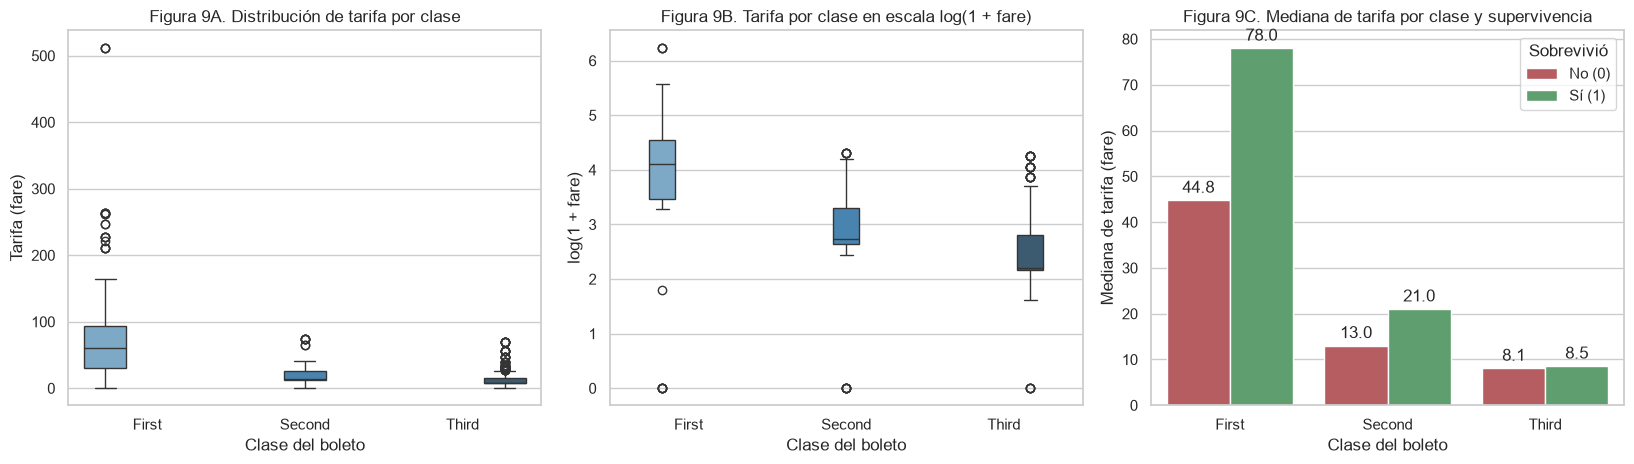

In [32]:
# ==================================================
# ANÁLISIS 4: COMPARACIÓN DE TARIFAS SEGÚN CLASE
# ==================================================

# 1. Estadísticas descriptivas de fare por clase
resumen_tarifa_clase = titanic_eda.groupby("class", observed=False)["fare"].agg(
    n="count",
    Media=lambda s: round(s.mean(), 2),
    DE=lambda s: round(s.std(), 2),
    Mediana=lambda s: round(s.median(), 2),
    Q25=lambda s: round(s.quantile(0.25), 2),
    Q75=lambda s: round(s.quantile(0.75), 2),
    IQR=lambda s: round(s.quantile(0.75) - s.quantile(0.25), 2),
    Min="min",
    Max=lambda s: round(s.max(), 2)
)
print("Tabla 4A. Estadísticas descriptivas de tarifa (fare) por clase:")
display(resumen_tarifa_clase)

# 2. Revisión de casos borde: tarifas = 0 y tarifas máximas
tarifa_cero = titanic_eda[titanic_eda["fare"] == 0]
print(f"\nPasajeros con fare == 0: {len(tarifa_cero)} registros (distribución por clase: {tarifa_cero['class'].value_counts().to_dict()})")

# 3. Mediana de tarifa por clase y condición de supervivencia
tarifa_clase_surv = pd.pivot_table(
    titanic_eda, index="class", columns="survived", values="fare", aggfunc="median", observed=False
).round(2)
tarifa_clase_surv.columns = ["Mediana_fare_NoSobrevivio", "Mediana_fare_Sobrevivio"]
print("\nTabla 4B. Mediana de tarifa por clase y supervivencia:")
display(tarifa_clase_surv)

# 4. Visualización
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# Panel A: Boxplot estándar de fare por clase
sns.boxplot(
    data=titanic_eda, x="class", y="fare",
    palette="Blues_d", hue="class", legend=False, ax=axes[0]
)
axes[0].set_title("Figura 9A. Distribución de tarifa por clase")
axes[0].set_xlabel("Clase del boleto")
axes[0].set_ylabel("Tarifa (fare)")

# Panel B: Boxplot en escala logarítmica para apreciar solapamientos
titanic_eda["log_fare"] = np.log1p(titanic_eda["fare"])
sns.boxplot(
    data=titanic_eda, x="class", y="log_fare",
    palette="Blues_d", hue="class", legend=False, width=0.5, ax=axes[1]
)
axes[1].set_title("Figura 9B. Tarifa por clase en escala log(1 + fare)")
axes[1].set_xlabel("Clase del boleto")
axes[1].set_ylabel("log(1 + fare)")

# Panel C: Mediana de tarifa según clase y supervivencia
sns.barplot(
    data=titanic_eda, x="class", y="fare", hue="survived",
    estimator=np.median, errorbar=None, palette=["#C44E52", "#55A868"], ax=axes[2]
)
axes[2].set_title("Figura 9C. Mediana de tarifa por clase y supervivencia")
axes[2].set_xlabel("Clase del boleto")
axes[2].set_ylabel("Mediana de tarifa (fare)")
axes[2].legend(title="Sobrevivió", labels=["No (0)", "Sí (1)"])
for container in axes[2].containers:
    axes[2].bar_label(container, fmt="%.1f", padding=3)

plt.tight_layout()
fig.savefig(raiz_proyecto / "figuras" / "09_tarifas.png", dpi=300, bbox_inches="tight")
plt.show()

Las medianas por clase son 60,29, 14,25 y 8,05. En primera clase, las medianas de sobrevivientes y no sobrevivientes son 77,96 y 44,75. Existen 15 tarifas cero cuyo origen no puede determinarse con estas variables. La transformación log1p facilita la visualización sin eliminar ceros.

Los IQR por clase son 62,58, 13,00 y 7,75; primera clase presenta la mayor dispersión. Las medianas de no sobrevivientes frente a sobrevivientes son 44,75 frente a 77,96 en primera, 13,00 frente a 21,00 en segunda y 8,05 frente a 8,52 en tercera. La figura 9 muestra que la asociación descriptiva entre tarifa y supervivencia varía por clase. No se demuestra que pagar más cause una mayor supervivencia.


## 12. Síntesis de hallazgos
| Pregunta | Evidencia | Respuesta |
|---|---|---|
| P1. Supervivencia general | §10, figura 1 | 342/891 (38,38 %) sobrevivieron. |
| P2. Sexo | §11.1, figura 6 | Mujeres 74,20 %; hombres 18,89 %. |
| P3. Clase | §11.1, figura 6 | Primera 62,96 %, segunda 47,28 %, tercera 24,24 %. |
| P4. Edad | §11.2, figura 7 | Hasta 12 años: 57,97 %; mayores de 60: 22,73 %; 714 edades válidas. |
| P5. Calidad | §7–8, D1–D6 | 107 filas adicionales idénticas; cubierta 77,22 % y edad 19,87 % faltantes; tres recodificaciones excluidas. |
| P6. Distribuciones | §9, figuras 2–5 | Edad: mediana 28; tarifa: mediana 14,45 y media 32,20; 537 pasajeros sin familiares registrados. |
| P7. Familia y tarifa | §11.3–11.4, figuras 8–9 | Supervivencia 30,35 %, 57,88 % y 16,13 % por grupo familiar; medianas tarifarias 60,29, 14,25 y 8,05 por clase. |

## 13. Supuestos y limitaciones
Se asume que las codificaciones del CSV describen los registros disponibles. No se conoce un diseño de muestreo que permita generalizar a todas las personas a bordo. La falta de identificadores impide confirmar duplicaciones reales o identificar familias únicas. La ausencia de edad y cubierta varía por clase; los análisis con casos disponibles pueden presentar sesgo de selección. Las tasas de grupos pequeños son sensibles a pocos registros. La tarifa registrada no permite establecer el costo individual de boletos compartidos. Las comparaciones son descriptivas y no controlan factores de confusión ni demuestran causalidad.

## 14. Conclusiones y próximos pasos
El análisis responde las siete preguntas y conserva las 891 observaciones originales. Las diferencias por sexo y clase son marcadas: la supervivencia femenina supera a la masculina en 55,31 puntos porcentuales y la primera clase supera a la tercera en 38,72 puntos. La edad y el tamaño familiar muestran patrones descriptivos no monotónicos que no se resumen adecuadamente con una sola media. La tarifa presenta asimetría positiva y diferencias entre clases. Las decisiones D1–D6 mantienen trazabilidad y evitan imputaciones o eliminaciones de filas sin evidencia suficiente.

En una fase posterior se propone estudiar el mecanismo de ausencia de edad, comparar estrategias de imputación y realizar análisis de sensibilidad respecto de filas idénticas y valores extremos. También conviene evaluar asociaciones ajustadas por sexo, clase, edad y tamaño familiar, y controlar redundancias o fuga de información antes de cualquier modelamiento. Estas propuestas no constituyen resultados de esta fase.

## 15. Reproducibilidad y referencias
Ejecutar desde la raíz o notebooks/ con las dependencias de requirements.txt y el archivo versionado datos/titanic.csv. Reiniciar el kernel y ejecutar todas las celdas. Las nueve figuras se guardan en figuras/ y la copia analítica en datos/titanic_eda_f1.csv. Se registra la huella SHA-256 del CSV original y se verifica que el DataFrame original no se modificó. Los notebooks individuales se conservan como antecedentes de los aportes. Las decisiones metodológicas requieren ratificación del equipo.


In [33]:
import hashlib
print("SHA-256 del CSV original:", hashlib.sha256(ruta_datos.read_bytes()).hexdigest())
pd.testing.assert_frame_equal(titanic_raw, pd.read_csv(ruta_datos))
assert titanic_eda.survived.sum() == 342
assert len(registro_decisiones) == 6
print("Dimensiones finales:", titanic_eda.shape)
print("Validaciones correctas")

ruta_salida = raiz_proyecto / "datos" / "titanic_eda_f1.csv"
titanic_eda.to_csv(ruta_salida, index=False)
assert pd.read_csv(ruta_salida).shape == titanic_eda.shape
print("CSV analítico:", ruta_salida.relative_to(raiz_proyecto))


SHA-256 del CSV original: 43af81a01f25a7771c9a42809a31625f4d0de3f335cdf29961f9ba179a86c13d
Dimensiones finales: (891, 15)
Validaciones correctas
CSV analítico: datos\titanic_eda_f1.csv


## Referencias

- Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical statistics for data scientists: 50+ essential concepts using R and Python* (2nd ed.). O'Reilly Media.

- Paraíso, S. (2026). *Resumen aplicado del libro: EDA mínimo viable* [Apunte]. Universidad Andrés Bello.

- The pandas development team. (s. f.). *pandas documentation*. https://pandas.pydata.org/docs/

- Waskom, M. (s. f.). *seaborn-data* [Repositorio de datos]. GitHub. https://github.com/mwaskom/seaborn-data

- Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021
